# Treino 2: comparação de modelos de churn

**Problema de negócio:** prever a probabilidade de churn de cada usuário nos próximos 28 dias,
listar os 50 clientes com maior risco e direcionar a eles uma ação de retenção.

**Target:** `flAtivacao = 1` indica que o usuário foi ativo nos 28 dias seguintes à `dtRef`.
O churn é o complemento: `prob_churn = 1 − prob_ativacao`.
Safras mensais, com um registro por cliente em cada safra.

O modelo estima `flAtivacao` a partir da ABT `workspace.analytics.abt_ativacao` e compara
quatro algoritmos de árvore (Random Forest, XGBoost, CatBoost e LightGBM).

**Fluxo (SEMMA):**
- **Sample:** separação em treino, teste e OOT
- **Explore:** nulos, médias por classe, qualidade das features, poder discriminante (IV, KS, AUC) e correlação
- **Modify:** imputação e seleção de features
- **Model:** GridSearch com validação cruzada, rastreado no MLflow
- **Assess:** comparação dos algoritmos, escolha manual, importância das features, score e lift

**Bases de avaliação:**

| Base | Origem | Uso |
|---|---|---|
| Treino | 80% das safras anteriores à mais recente | EDA, ajuste da imputação, validação cruzada |
| Teste | 20% das safras anteriores (estratificado) | Avaliação holdout no mesmo período do treino |
| OOT | Safra mais recente (dtRef 2026-06-01) | Avaliação fora do tempo; nunca entra em nenhum treino |

**Saídas:**
- Uma run por algoritmo no experimento MLflow `1153922304569438`, com as tags `algoritmo` e `lote`
- Modelo final (reajustado em treino + teste) logado como `model-refit` em cada run
- Tag `modelo_escolhido` (sim/nao) e gráfico e tabela de feature importance na run escolhida
- `df_score`: probabilidade de ativação e de churn por cliente na safra OOT

### Instalação de dependências
Instala as bibliotecas que não vêm no runtime: `feature_engine` (imputadores), `xgboost`,
`catboost` e `lightgbm`.

`dbutils.library.restartPython()` reinicia o interpretador para carregar as versões instaladas.
Qualquer variável criada antes desta célula é perdida, então ela deve ser sempre a primeira a rodar.

In [0]:
%pip install feature_engine xgboost catboost lightgbm
dbutils.library.restartPython()

Looking in indexes: [REDACTED]
Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


### Imports e configuração do MLflow
- `MLFLOW_DATABRICKS_TAGS_TO_SKIP = "extraContext"` impede que o MLflow anexe às runs a tag de
  contexto extra do Databricks.
- O logger `mlflow.tracking.context.registry` foi elevado para `ERROR`, para silenciar avisos de contexto.
- Importa os módulos do scikit-learn, os imputadores do feature_engine e as bibliotecas de boosting.

In [0]:
import os
import logging
os.environ["MLFLOW_DATABRICKS_TAGS_TO_SKIP"] = "extraContext"
logging.getLogger("mlflow.tracking.context.registry").setLevel(logging.ERROR)

import mlflow
from datetime import datetime
from sklearn import base
from sklearn import ensemble
from sklearn import linear_model
from sklearn import pipeline
from sklearn import metrics
from sklearn import model_selection
from feature_engine import imputation

import xgboost
import lightgbm
import catboost
from sklearn import tree

### Sample: separação em treino, teste e OOT
1. Lê a ABT inteira para pandas com `toPandas()`. Isso é viável no volume atual (cerca de 2,4 mil linhas).
2. **OOT** = linhas da `dtRef` mais recente. Simula a aplicação do modelo numa safra futura.
3. As demais safras são divididas em treino e teste (80/20) com `train_test_split`, estratificado
   pelo target para manter a mesma taxa de ativação nas duas bases (`random_state=42`).
4. **Features** = todas as colunas, exceto as duas primeiras (`dtRef` e id do cliente) e a última (target).

> ⚠️ A seleção de colunas usa a **posição** (`columns[2:-1]`), mas o target é lido pelo **nome**.
> Se a ABT ganhar uma coluna nova no final, essa coluna sai das features e `flAtivacao` entra como
> feature, o que causa vazamento de target.

**Resultado:** treino 1.723 linhas (27,05% de ativação), teste 431 (27,15%) e OOT 239 (56,07%).
O "100%" impresso para o OOT é a proporção dele sobre ele mesmo.

> A taxa de ativação do OOT é o dobro da taxa do treino. A AUC não depende da prevalência,
> mas o lift e a calibração das probabilidades dependem. Isso deve ser levado em conta ao ler as métricas do OOT.

In [0]:
# SAMPLE
df_abt = spark.table("workspace.analytics.abt_ativacao").toPandas()
df_oot = df_abt[df_abt['dtRef']==df_abt['dtRef'].max()]

df_train_test = df_abt[df_abt['dtRef']!=df_abt['dtRef'].max()]

target = 'flAtivacao'
features = df_train_test.columns.tolist()[2:-1]
X = df_train_test[features]
y = df_train_test[target]

X_train, X_test, y_train, y_test = model_selection.train_test_split(X, y,
                                                                    random_state=42,
                                                                    stratify=y,
                                                                    test_size=0.2)


print(f"Tamanho da base Treino: {y_train.shape[0]} ({y_train.shape[0]/y.shape[0]*100:.2f}%). Taxa respoata: ({y_train.mean()*100:.2f}%)")

print(f"Tamanho da base Test: {y_test.shape[0]} ({y_test.shape[0]/y.shape[0]*100:.2f}%). Taxa resposta: ({y_test.mean()*100:.2f}%)")

print(f"Tamanho da base OOT: {df_oot[target].shape[0]} ({df_oot[target].shape[0]/df_oot.shape[0]*100:.2f}%). Taxa resposta: ({df_oot[target].mean()*100:.2f}%)")

Tamanho da base Treino: 1723 (79.99%). Taxa respoata: (27.05%)
Tamanho da base Test: 431 (20.01%). Taxa resposta: (27.15%)
Tamanho da base OOT: 239 (100.00%). Taxa resposta: (56.07%)


### Conferência do tamanho do OOT
Verificação pontual do número de linhas da safra OOT (239). Não altera nenhuma variável.

In [0]:
df_oot[target].shape[0]

239

### Amostra das features de treino
Mostra as 5 primeiras linhas das 51 features candidatas. As colunas de cursos
(`python_2025`, `sql_2020` etc.) aparecem majoritariamente nulas, o que motiva a próxima célula.

In [0]:
X_train.head()

,qtFrequencia,qtPontos,qtPontosPositivos,recencia,QtdeTransacoes,zScore,pctTransacaoChatMessage,pctTransacaoListapresenca,pctTransacaoPresencaStreak,pctTransacaoResgatarPonei,pctTransacaoTrocaPontosStreamElements,flStreak,DiasUltimoStreak,qtdeProdutoDistintos,saldoDia,diasPrimeiraTransacao,freqVida,qtdCursosIniciados,qtdCursosFinalizados,python_2025,plataforma_ml_2026,mlflow_2025,carreira,nekt_2025,estatistica_2025,coleta_dados_2024,python_2024,lago_mago_2024,github_2025,trampar_lakehouse_2024,ds_databricks_2024,sql_2020,ds_pontos_2024,streamlit_2025,estatistica_2024,ml_2024,ragia,sql_2025,loyalty_predict_2025,go_2026,f1_lake,ia_canal_2025,tse_analytics_2024,machine_learning_2025,matchmaking_trampar_de_casa_2024,pandas_2024,pandas_2025,speed_f1,github_2024,avgTempoInicioUltimo,avgTempoInicioFim
526,5,207,207,5,11,-0.134856,0.272727,0.363636,0.0,0.0,0.0,0,NaN,3,1502,255,31,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1219,3,150,150,14,3,-0.408940,0.000000,1.000000,0.0,0.0,0.0,0,NaN,1,3866,487,61,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1032,1,50,50,5,1,-0.520840,0.000000,1.000000,0.0,0.0,0.0,0,NaN,1,306,325,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1886,2,118,118,23,20,-0.394452,0.850000,0.100000,0.0,0.0,0.0,0,NaN,3,168,84,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1726,1,50,50,9,1,-0.471428,0.000000,1.000000,0.0,0.0,0.0,0,NaN,1,305,478,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Explore: proporção de nulos
Calcula a fração de nulos de cada feature **no treino** e lista apenas as que têm algum nulo.
Os comentários registram a estratégia de imputação definida para cada grupo:

| Feature(s) | % nulos | Significado do nulo | Imputação |
|---|---|---|---|
| `DiasUltimoStreak` | 92% | Cliente sem streak na janela | Máximo (28 dias, ou seja, "o mais distante possível") |
| `qtdCursos*` e colunas de cursos | 84% | Sem registro em cursos | 0 |
| `avgTempoInicioUltimo`, `avgTempoInicioFim` | 84% / 89% | Sem cursos iniciados ou finalizados | Máximo observado |

In [0]:
# EXPLORE

is_na = X_train.isna().mean()
is_na[is_na>0]

# DiasUltimoStreak -> 28 dias

# qtdCursosIniciados -> 0
# qtdCursosFinalizados -> 0
# python_2025 -> 0
# plataforma_ml_2026 -> 0
# mlflow_2025 -> 0
# carreira -> 0
# nekt_2025 -> 0
# estatistica_2025 -> 0
# coleta_dados_2024 -> 0
# python_2024 -> 0
# lago_mago_2024 -> 0
# github_2025 -> 0
# trampar_lakehouse_2024 -> 0
# ds_databricks_2024 -> 0
# sql_2020 -> 0
# ds_pontos_2024 -> 0
# streamlit_2025 -> 0
# estatistica_2024 -> 0
# ml_2024 -> 0
# ragia -> 0
# sql_2025 -> 0
# loyalty_predict_2025 -> 0
# go_2026 -> 0
# f1_lake -> 0
# ia_canal_2025 -> 0
# tse_analytics_2024 -> 0
# machine_learning_2025 -> 0
# matchmaking_trampar_de_casa_2024 -> 0
# pandas_2024 -> 0
# pandas_2025 -> 0
# speed_f1 -> 0
# github_2024 -> 0

# avgTempoInicioUltimo -> max base
# avgTempoInicioFim -> max base

DiasUltimoStreak                    0.918746
qtdCursosIniciados                  0.842716
qtdCursosFinalizados                0.842716
python_2025                         0.842716
plataforma_ml_2026                  0.842716
mlflow_2025                         0.842716
carreira                            0.842716
nekt_2025                           0.842716
estatistica_2025                    0.842716
coleta_dados_2024                   0.842716
python_2024                         0.842716
lago_mago_2024                      0.842716
github_2025                         0.842716
trampar_lakehouse_2024              0.842716
ds_databricks_2024                  0.842716
sql_2020                            0.842716
ds_pontos_2024                      0.842716
streamlit_2025                      0.842716
estatistica_2024                    0.842716
ml_2024                             0.842716
ragia                               0.842716
sql_2025                            0.842716
loyalty_pr

### Modify: definição dos imputadores
- `ArbitraryNumberImputer(arbitrary_number=0)`: preenche com 0 as features de cursos (`features_0`).
- `EndTailImputer(imputation_method="max", fold=1)`: preenche com o valor máximo **aprendido no treino**
  (máximo × `fold`; com `fold=1`, é o próprio máximo).

Aqui os objetos são apenas criados. O `fit` acontece dentro do pipeline, em cada fold da validação
cruzada, o que evita vazamento de informação do teste e do OOT.

In [0]:
# MODIFY

features_0 = [
    'qtdCursosIniciados',
    'qtdCursosFinalizados',
    'python_2025',
    'plataforma_ml_2026',
    'mlflow_2025',
    'carreira',
    'nekt_2025',
    'estatistica_2025',
    'coleta_dados_2024',
    'python_2024',
    'lago_mago_2024',
    'github_2025',
    'trampar_lakehouse_2024',
    'ds_databricks_2024',
    'sql_2020',
    'ds_pontos_2024',
    'streamlit_2025',
    'estatistica_2024',
    'ml_2024',
    'ragia',
    'sql_2025',
    'loyalty_predict_2025',
    'go_2026',
    'f1_lake',
    'ia_canal_2025',
    'tse_analytics_2024',
    'machine_learning_2025',
    'matchmaking_trampar_de_casa_2024',
    'pandas_2024',
    'pandas_2025',
    'speed_f1',
    'github_2024',
]

imput_0 = imputation.ArbitraryNumberImputer(variables=features_0, arbitrary_number=0)

imput_max_tail = imputation.EndTailImputer(variables=['DiasUltimoStreak','avgTempoInicioUltimo','avgTempoInicioFim'],
                                           imputation_method='max', fold=1)

### Explore: médias por classe após a imputação
- Usa **cópias** (`base.clone`) dos imputadores, para não alterar os objetos usados no pipeline de treino.
- Ajusta a imputação somente em `X_train` e calcula a média de cada feature entre ativados (1) e não ativados (0).
- `rate = média(1) / média(0)`: acima de 1, a feature é maior entre os que ativam; abaixo de 1, menor.
  `inf` indica média zero nos não ativados; `NaN` indica média zero nas duas classes (feature constante).

> As features imputadas com o máximo (`DiasUltimoStreak`, `avgTempo*`) misturam taxa de nulos com a
> distribuição real, então o `rate` delas não deve ser lido isoladamente.

In [0]:
# EXPLORE (features imputadas)
# Usa CÓPIAS dos imputadores: imput_0 e imput_max_tail, usados no pipeline de treino, não são alterados.
# Tudo é calculado só em X_train (sem olhar teste ou OOT).

from sklearn import base
from sklearn import pipeline

imputacao_eda = pipeline.Pipeline(steps=[
    ('imputacao_0', base.clone(imput_0)),
    ('imput_max', base.clone(imput_max_tail)) ])

X_train_eda = imputacao_eda.fit_transform(X_train)

df_train_eda = X_train_eda.copy()
df_train_eda[target] = y_train
sumario = df_train_eda.groupby(target)[features].mean().T
sumario['rate'] = sumario[1] / sumario[0]

# Atenção: DiasUltimoStreak, avgTempoInicioUltimo e avgTempoInicioFim têm nulos trocados pelo máximo,
# então a média delas mistura taxa de nulos com distribuição real.
sumario.sort_values('rate', ascending=False)

flAtivacao,0,1,rate
nekt_2025,0.000000,0.002146,inf
speed_f1,0.000000,0.001431,inf
f1_lake,0.000000,0.000058,inf
streamlit_2025,0.000088,0.005961,67.435622
github_2024,0.000796,0.006438,8.092275
machine_learning_2025,0.003469,0.026009,7.498346
flStreak,0.034208,0.208155,6.084889
loyalty_predict_2025,0.002310,0.012183,5.274964
pctTransacaoTrocaPontosStreamElements,0.000398,0.001840,4.625772
freqVida,6.832140,30.727468,4.497488


### Explore: qualidade e distribuição das features imputadas
Para cada feature, calcula média, mediana, desvio, mínimo, máximo, número de valores distintos,
% de zeros e % do valor mais comum.

**Quase constante** = um único valor ocupa 99% ou mais da base de treino. Resultado: **21 de 51**
features, quase todas colunas de cursos. Elas trazem pouca informação e tendem a adicionar ruído ao modelo.

In [0]:
# EXPLORE - QUALIDADE E DISTRIBUIÇÃO DAS FEATURES IMPUTADAS
import numpy as np
import pandas as pd

desc_eda = pd.DataFrame({
    "media": X_train_eda.mean(),
    "mediana": X_train_eda.median(),
    "desvio": X_train_eda.std(),
    "minimo": X_train_eda.min(),
    "maximo": X_train_eda.max(),
    "n_unicos": X_train_eda.nunique(),
    "pct_zeros": (X_train_eda == 0).mean() * 100,
    "pct_valor_mais_comum": X_train_eda.apply(lambda s: s.value_counts(normalize=True).iloc[0] * 100),
})

# Quase constante: um único valor ocupa 99% ou mais da base de treino
desc_eda["quase_constante"] = desc_eda["pct_valor_mais_comum"] >= 99

print(f"Features quase constantes: {desc_eda['quase_constante'].sum()} de {len(desc_eda)}")
desc_eda.sort_values("pct_valor_mais_comum", ascending=False).round(3).reset_index(names="feature")

Features quase constantes: 21 de 51


,feature,media,mediana,desvio,minimo,maximo,n_unicos,pct_zeros,pct_valor_mais_comum,quase_constante
0,plataforma_ml_2026,0.000,0.000,0.000,0.000,0.000,1,100.000,100.000,True
1,ia_canal_2025,0.000,0.000,0.000,0.000,0.000,1,100.000,100.000,True
2,ragia,0.000,0.000,0.000,0.000,0.000,1,100.000,100.000,True
3,matchmaking_trampar_de_casa_2024,0.000,0.000,0.000,0.000,0.000,1,100.000,100.000,True
4,ds_databricks_2024,0.000,0.000,0.003,0.000,0.111,2,99.942,99.942,True
5,f1_lake,0.000,0.000,0.001,0.000,0.027,2,99.942,99.942,True
6,tse_analytics_2024,0.000,0.000,0.003,0.000,0.125,2,99.942,99.942,True
7,ds_pontos_2024,0.000,0.000,0.003,0.000,0.125,2,99.942,99.942,True
8,nekt_2025,0.001,0.000,0.024,0.000,1.000,2,99.942,99.942,True
9,go_2026,0.000,0.000,0.009,0.000,0.314,3,99.884,99.884,True


### Explore: poder discriminante univariado (IV, KS e AUC)
Mede o quanto cada feature, **sozinha**, separa quem ativa de quem não ativa:
- **Faixas:** features com até 10 valores distintos ficam como estão; as demais são divididas em decis
  (`qcut`, descartando limites repetidos).
- **IV** = Σ (dist_eventos − dist_não_eventos) × ln(dist_eventos / dist_não_eventos). Soma-se 0,5 a cada
  faixa (suavização) para evitar log de zero.
- **KS** = máximo de |TPR − FPR| usando a própria feature como score.
- **AUC univariado** = max(AUC, 1 − AUC), para que a direção não importe. A coluna `direcao` indica o sentido.
- **Força do IV:** < 0,02 sem poder | 0,02–0,1 fraco | 0,1–0,3 médio | > 0,3 forte.

O gráfico mostra o top 20 por IV, com as linhas de referência.

**Resultado:** 11 features fortes e 2 médias. Sete features têm IV acima de 0,5 (`qtFrequencia` 1,01,
`freqVida`, `saldoDia`, `QtdeTransacoes`, `recencia`, `qtdeProdutoDistintos`, `qtPontosPositivos`) e,
como diz o comentário da célula, merecem checagem de vazamento.

> **Limitação:** em features muito concentradas num único valor (ex.: `DiasUltimoStreak`,
> `pctTransacaoPresencaStreak`), os decis colapsam numa só faixa e o IV sai 0, mesmo com KS de 0,17.
> Para elas, o KS e o AUC são mais confiáveis que o IV.

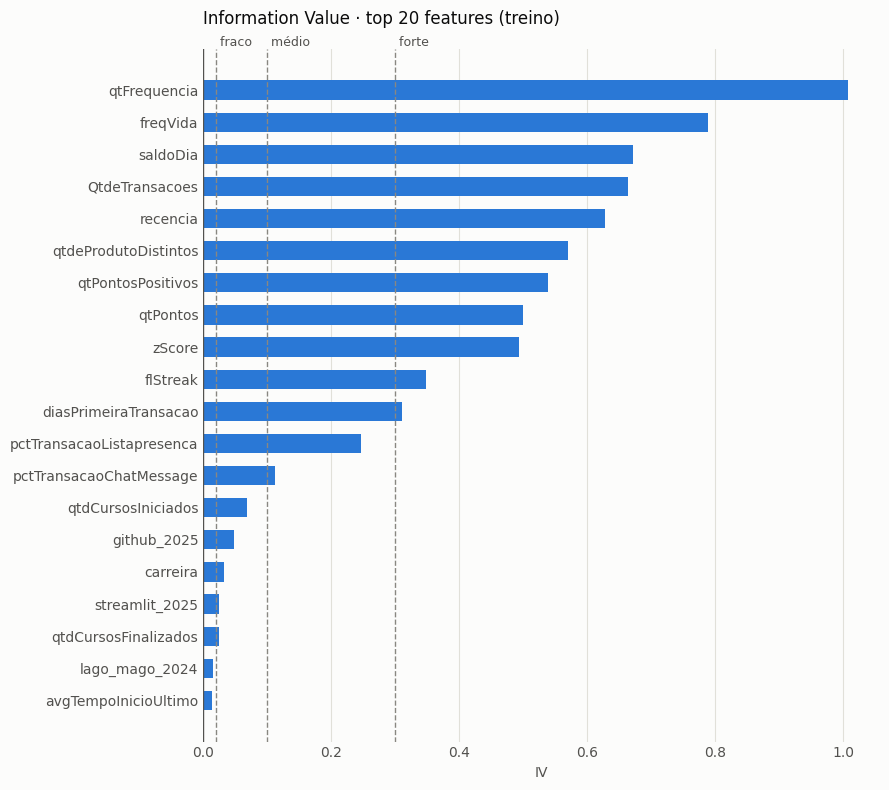

,feature,iv,ks,auc_univariado,direcao,forca_iv
0,qtFrequencia,1.0068,0.3897,0.7421,"maior valor, mais ativação",forte
1,freqVida,0.7885,0.3880,0.7420,"maior valor, mais ativação",forte
2,saldoDia,0.6706,0.3540,0.7179,"maior valor, mais ativação",forte
3,QtdeTransacoes,0.6636,0.3364,0.7225,"maior valor, mais ativação",forte
4,recencia,0.6281,0.3272,0.7094,"maior valor, menos ativação",forte
5,qtdeProdutoDistintos,0.5691,0.2702,0.6800,"maior valor, mais ativação",forte
6,qtPontosPositivos,0.5390,0.3256,0.6915,"maior valor, mais ativação",forte
7,qtPontos,0.4995,0.2902,0.6637,"maior valor, mais ativação",forte
8,zScore,0.4934,0.3236,0.6857,"maior valor, mais ativação",forte
9,flStreak,0.3479,0.1739,0.5870,"maior valor, mais ativação",forte


In [0]:
# EXPLORE - PODER DISCRIMINANTE UNIVARIADO (IV, KS E AUC)
# Mede o quanto cada feature, sozinha, separa quem ativa de quem não ativa.
# Referência usual de IV: < 0.02 sem poder | 0.02 a 0.1 fraco | 0.1 a 0.3 médio | > 0.3 forte
# IV acima de 0.5 merece checagem de vazamento (a feature pode estar "vendo" o target).

import matplotlib.pyplot as plt
from sklearn import metrics

def faixas_eda(x, n_faixas=10):
    """Features com poucos valores ficam como estão; as demais viram faixas de quantil."""
    if x.nunique() <= n_faixas:
        return x
    return pd.qcut(x, q=n_faixas, duplicates="drop")

def iv_eda(x, y, n_faixas=10):
    tab = pd.crosstab(faixas_eda(x, n_faixas), y)
    if tab.shape[0] < 2 or tab.shape[1] < 2:
        return 0.0
    # +0.5 evita divisão por zero em faixas sem eventos ou sem não eventos
    dist_evento = (tab[1] + 0.5) / (tab[1].sum() + 0.5 * len(tab))
    dist_nao_evento = (tab[0] + 0.5) / (tab[0].sum() + 0.5 * len(tab))
    return float(((dist_evento - dist_nao_evento) * np.log(dist_evento / dist_nao_evento)).sum())

linhas = []
for col in X_train_eda.columns:
    x = X_train_eda[col]
    auc = metrics.roc_auc_score(y_train, x)
    fpr, tpr, _ = metrics.roc_curve(y_train, x)
    linhas.append({"feature": col,
                   "iv": iv_eda(x, y_train),
                   "ks": float(np.max(np.abs(tpr - fpr))),
                   "auc_univariado": max(auc, 1 - auc),
                   "direcao": "maior valor, mais ativação" if auc >= 0.5 else "maior valor, menos ativação"})

ranking_eda = pd.DataFrame(linhas).sort_values("iv", ascending=False).reset_index(drop=True)
ranking_eda["forca_iv"] = pd.cut(ranking_eda["iv"], bins=[-np.inf, 0.02, 0.1, 0.3, np.inf],
                                 labels=["sem poder", "fraco", "médio", "forte"])

# GRÁFICO: top N por IV, com as linhas de referência que cabem na escala
top_n_eda = 20
df_plot_iv = ranking_eda.head(top_n_eda).iloc[::-1]

fig_iv, ax = plt.subplots(figsize=(9, 0.32 * len(df_plot_iv) + 1.6))
fig_iv.patch.set_facecolor("#fcfcfb")
ax.set_facecolor("#fcfcfb")

ax.barh(df_plot_iv["feature"], df_plot_iv["iv"], height=0.6, color="#2a78d6")
ax.axvline(0, color="#52514e", linewidth=1)
for limite, rotulo in [(0.02, "fraco"), (0.1, "médio"), (0.3, "forte")]:
    if limite <= df_plot_iv["iv"].max():
        ax.axvline(limite, color="#898781", linewidth=1, linestyle="--")
        ax.text(limite, 1.0, f" {rotulo}", transform=ax.get_xaxis_transform(), color="#52514e", fontsize=9, va="bottom")

ax.set_title(f"Information Value · top {top_n_eda} features (treino)", loc="left", color="#0b0b0b", fontsize=12, pad=18)
ax.set_xlabel("IV", color="#52514e")
ax.tick_params(colors="#52514e", length=0)
ax.grid(axis="x", color="#e1e0d9", linewidth=0.8)
ax.set_axisbelow(True)
for lado in ["top", "right", "left", "bottom"]:
    ax.spines[lado].set_visible(False)
plt.tight_layout()
plt.show()

ranking_eda.round(4)

### Explore: correlação entre features (redundância)
- Usa **Spearman**, que capta relações monotônicas e é robusto a caudas longas.
- Lista os pares com |ρ| ≥ 0,8. Resultado: **12 pares**.
- O mapa de calor mostra todas as features, ordenadas por agrupamento hierárquico (ligação média,
  distância = 1 − |ρ|), para que grupos redundantes apareçam como blocos. A diagonal fica oculta.

**Grupos principais:**
- Streak: `flStreak`, `pctTransacaoPresencaStreak`, `DiasUltimoStreak`
- Cursos: `qtdCursos*`, `avgTempo*`
- Pontos: `qtPontos`, `qtPontosPositivos`, `zScore`

Features redundantes dividem a importância entre si. Isso atrapalha pouco a predição de modelos de
árvore, mas dificulta a interpretação.

Pares com |correlação| >= 0.8: 12


feature_1,feature_2,spearman
pctTransacaoPresencaStreak,flStreak,0.999
flStreak,DiasUltimoStreak,-0.995
pctTransacaoPresencaStreak,DiasUltimoStreak,-0.993
qtdCursosFinalizados,avgTempoInicioFim,-0.993
qtdCursosIniciados,avgTempoInicioUltimo,-0.986
qtPontos,qtPontosPositivos,0.939
qtPontosPositivos,zScore,0.896
qtdCursosIniciados,qtdCursosFinalizados,0.853
qtdCursosIniciados,avgTempoInicioFim,-0.847
qtPontos,zScore,0.837


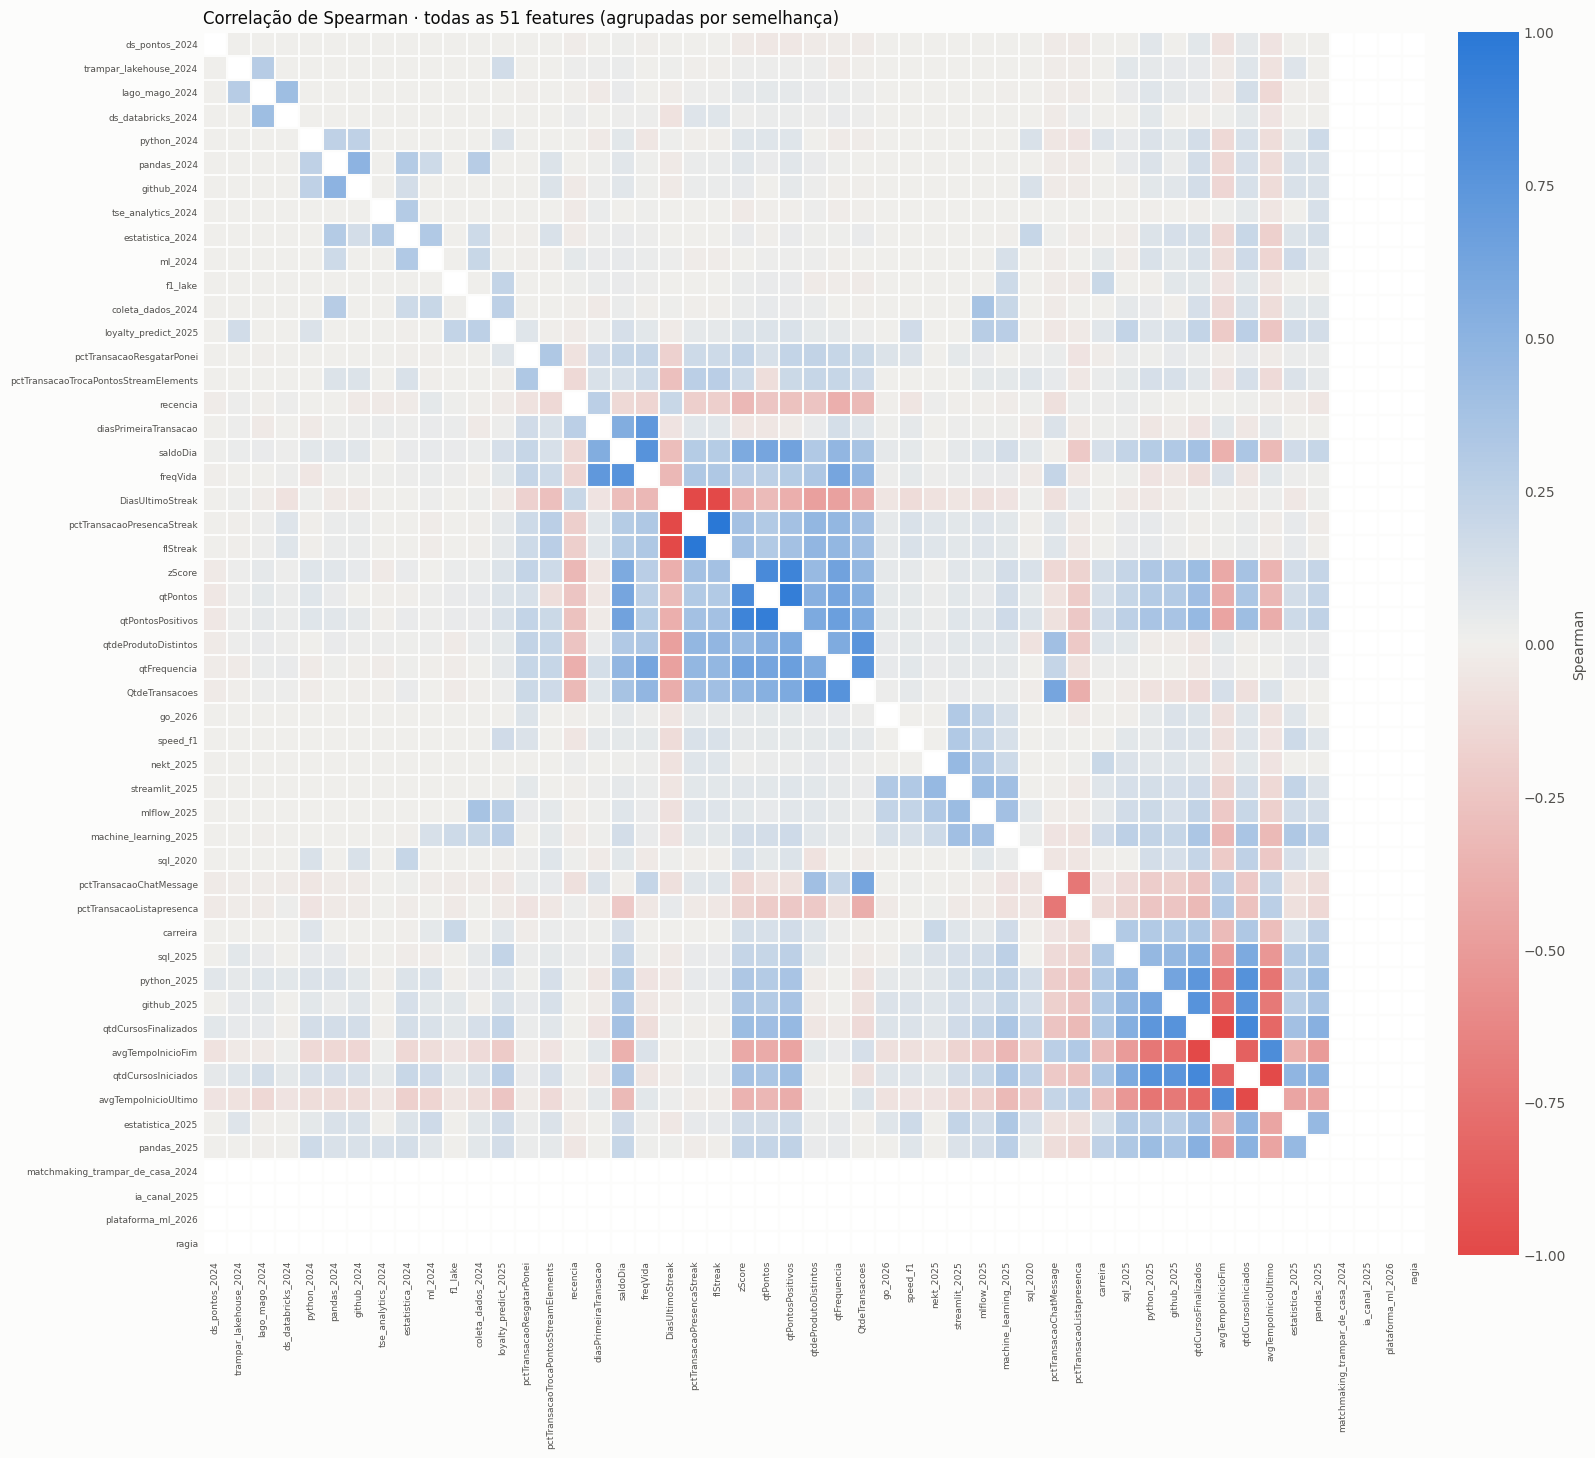

In [0]:
# EXPLORE - CORRELAÇÃO ENTRE FEATURES (REDUNDÂNCIA)
# Spearman capta relações monotônicas e é robusto a caudas longas.
# Pares muito correlacionados carregam a mesma informação e dividem a importância no permutation importance.

from matplotlib.colors import LinearSegmentedColormap

corr_eda = X_train_eda.corr(method="spearman")

mascara = np.triu(np.ones(corr_eda.shape, dtype=bool), k=1)
pares_eda = corr_eda.where(mascara).stack().rename("spearman").reset_index()
pares_eda.columns = ["feature_1", "feature_2", "spearman"]
pares_altos_eda = (pares_eda[pares_eda["spearman"].abs() >= 0.8]
                   .sort_values("spearman", key=abs, ascending=False)
                   .reset_index(drop=True))

print(f"Pares com |correlação| >= 0.8: {len(pares_altos_eda)}")
display(pares_altos_eda.round(3))

# GRÁFICO: matriz de correlação de TODAS as features
# A ordem vem de um agrupamento hierárquico (distância = 1 - |Spearman|):
# features parecidas ficam vizinhas e os grupos redundantes aparecem como blocos.
from scipy.cluster import hierarchy
from scipy.spatial.distance import squareform

distancia = (1 - corr_eda.abs().fillna(0)).to_numpy(copy=True)  # fillna: feature constante não tem correlação
np.fill_diagonal(distancia, 0)
ordem = hierarchy.leaves_list(hierarchy.linkage(squareform(distancia, checks=False), method="average"))
todas_corr = corr_eda.columns[ordem].tolist()

matriz = corr_eda.loc[todas_corr, todas_corr].to_numpy(copy=True)
np.fill_diagonal(matriz, np.nan)  # a diagonal é sempre 1: esconder destaca os pares que importam
cmap_div = LinearSegmentedColormap.from_list("divergente", ["#e34948", "#f0efec", "#2a78d6"])

n_corr = len(todas_corr)
lado_fig = max(9, 0.28 * n_corr + 3)       # o gráfico cresce com o número de features
fonte_corr = 8 if n_corr <= 25 else 6.5

fig_corr, ax = plt.subplots(figsize=(lado_fig, lado_fig * 0.85))
fig_corr.patch.set_facecolor("#fcfcfb")
im = ax.imshow(matriz, cmap=cmap_div, vmin=-1, vmax=1)

ax.set_xticks(range(n_corr))
ax.set_xticklabels(todas_corr, rotation=90, fontsize=fonte_corr)
ax.set_yticks(range(n_corr))
ax.set_yticklabels(todas_corr, fontsize=fonte_corr)
ax.tick_params(colors="#52514e", length=0)
# separa as células com uma linha da cor do fundo
ax.set_xticks(np.arange(-0.5, n_corr, 1), minor=True)
ax.set_yticks(np.arange(-0.5, n_corr, 1), minor=True)
ax.grid(which="minor", color="#fcfcfb", linewidth=1.5 if n_corr > 25 else 2)
ax.tick_params(which="minor", length=0)
for lado in ["top", "right", "left", "bottom"]:
    ax.spines[lado].set_visible(False)

cbar = fig_corr.colorbar(im, ax=ax, fraction=0.04, pad=0.02)
cbar.set_label("Spearman", color="#52514e")
cbar.outline.set_visible(False)
cbar.ax.tick_params(colors="#52514e", length=0)

ax.set_title(f"Correlação de Spearman · todas as {n_corr} features (agrupadas por semelhança)", loc="left", color="#0b0b0b", fontsize=12)
plt.tight_layout()
plt.show()

### Modify: seleção de features para o treino
Mantém 11 features: as de IV médio ou forte, exceto `qtPontos` e `zScore`, que são redundantes com
`qtPontosPositivos` (ρ de 0,94 e 0,90). Em cada par com |ρ| ≥ 0,8, foi mantida a feature de maior IV.

`X_train`, `X_test` e `X` são reduzidos às features selecionadas. `df_oot` não muda, porque as
células seguintes já usam `df_oot[features]`.

Os imputadores são **recriados** porque o feature_engine dá erro se a lista de variáveis contiver
colunas que não existem mais na base. Quando a lista fica vazia, o passo vira `"passthrough"`.

> Com a seleção atual, nenhuma das 11 features tem nulos. Os dois passos de imputação viram
> `passthrough` e o pipeline vai direto para o classificador. Se features de cursos ou de streak
> forem reincluídas, a imputação volta a agir automaticamente.

In [0]:
# MODIFY - SELEÇÃO DE FEATURES PARA O TREINO
from feature_engine import imputation

features = [
    'qtFrequencia',
    'freqVida',
    'saldoDia',
    'QtdeTransacoes',
    'recencia',
    'qtdeProdutoDistintos',
    'qtPontosPositivos',
    'flStreak',
    'diasPrimeiraTransacao',
    'pctTransacaoListapresenca',
    'pctTransacaoChatMessage'
]

X_train = X_train[features]
X_test = X_test[features]
X = X[features]
# df_oot não muda: as células seguintes já usam df_oot[features]

# OS IMPUTADORES PRECISAM SER REFEITOS: o feature_engine dá erro se a lista tiver colunas que saíram da base
vars_0 = [f for f in features_0 if f in features]
vars_max = [f for f in ['DiasUltimoStreak', 'avgTempoInicioUltimo', 'avgTempoInicioFim'] if f in features]

imput_0 = imputation.ArbitraryNumberImputer(variables=vars_0, arbitrary_number=0) if vars_0 else "passthrough"
imput_max_tail = imputation.EndTailImputer(variables=vars_max, imputation_method='max', fold=1) if vars_max else "passthrough"

### Algoritmos e grids de hiperparâmetros
Cada entrada de `modelos` contém o estimador, com os parâmetros fixos no construtor, e o grid
dos parâmetros que mais pesam. O prefixo `classificador__` aponta para o passo de mesmo nome no pipeline.

| Algoritmo | Fixos | Grid | Combinações | Fits (×5 folds) |
|---|---|---|---|---|
| Random Forest | 500 árvores | `min_samples_leaf`, `max_features`, `max_depth`, `max_samples` | 36 | 180 |
| XGBoost | `subsample` e `colsample_bytree` 0,8; `hist`; 300 árvores | `learning_rate`, `max_depth`, `min_child_weight`, `reg_lambda` | 36 | 180 |
| CatBoost | 500 iterações | `learning_rate`, `depth`, `l2_leaf_reg` | 18 | 90 |
| LightGBM | `subsample` e `colsample` 0,8, `subsample_freq=1`; 300 árvores | `learning_rate`, `num_leaves`, `min_child_samples`, `reg_lambda` | 24 | 120 |

No LightGBM, `subsample_freq=1` é obrigatório: sem ele, o `subsample` é ignorado.

In [0]:
# ALGORITMOS E GRIDS DE HIPERPARÂMETROS
# Parâmetros fixos no construtor = valores consolidados; o grid cobre só os que mais pesam
modelos = {

    "random_forest": (
        ensemble.RandomForestClassifier(n_estimators=500, random_state=42, n_jobs=-1),
        {
            "classificador__min_samples_leaf": [10, 100, 200],   # folhas maiores = menos overfitting
            "classificador__max_features": ["sqrt", 0.3, 0.5],
            "classificador__max_depth": [None, 12],
            "classificador__max_samples": [0.7, None],                   # cada árvore vê 70% ou 100% das linhas
        },
    ),

    "xgboost": (
        xgboost.XGBClassifier(subsample=0.8, colsample_bytree=0.8, tree_method="hist",
                              eval_metric="auc", random_state=42, n_jobs=-1),
        {
            "classificador__n_estimators": [300],
            "classificador__learning_rate": [0.03, 0.1],
            "classificador__max_depth": [3, 5, 7],
            "classificador__min_child_weight": [1, 10, 30],              # peso mínimo por folha
            "classificador__reg_lambda": [1, 10],                        # L2
        },
    ),

    "catboost": (
        catboost.CatBoostClassifier(eval_metric="AUC", random_seed=42, verbose=0, allow_writing_files=False),
        {
            "classificador__iterations": [500],
            "classificador__learning_rate": [0.03, 0.1],
            "classificador__depth": [4, 6, 8],
            "classificador__l2_leaf_reg": [1, 3, 10],                    # L2 (o padrão é 3)
        },
    ),

    "lightgbm": (
        # subsample_freq=1 É OBRIGATÓRIO: sem ele o LightGBM ignora o subsample
        lightgbm.LGBMClassifier(subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                                random_state=42, n_jobs=-1, verbose=-1),
        {
            "classificador__n_estimators": [300],
            "classificador__learning_rate": [0.03, 0.1],
            "classificador__num_leaves": [15, 31],
            "classificador__min_child_samples": [20, 100, 300],          # principal freio contra overfitting
            "classificador__reg_lambda": [0.0, 10.0],                    # L2
        },
    ),
}

### Model: treino, avaliação e registro no MLflow
1. Vincula o notebook ao experimento `1153922304569438` e gera um `lote` (timestamp) que identifica a execução.
2. `mlflow.sklearn.autolog(log_models=False, max_tuning_runs=5)`: registra o GridSearch e cria runs
   filhas só para os 5 melhores candidatos, sem salvar modelos automaticamente.
3. Para cada algoritmo, dentro de uma run com as tags `algoritmo` e `lote`:
   - monta o pipeline (imputação 0 → imputação máximo → classificador);
   - roda `GridSearchCV` com `StratifiedKFold` de 5 folds **apenas no treino**, otimizando ROC AUC.
     A imputação é ajustada dentro de cada fold, sem vazamento;
   - com o melhor pipeline (já reajustado no treino), calcula a AUC no treino, no teste e no OOT
     e loga os melhores parâmetros e as métricas;
   - **reajusta o pipeline em treino + teste** (`X`, `y`), mede a AUC no OOT (`auc_oot_refit`) e loga o
     modelo como `model-refit`. O OOT continua fora do treino, então essa avaliação segue válida.
4. Guarda tudo em `resultados[nome]`.

**Avisos esperados na saída:**
- *"Inferred schema contains integer column(s)"*: as colunas inteiras não têm nulos. Se chegarem
  nulos em produção, a validação de schema pode falhar.
- *"Parameter with key verbose was already logged"*: conflito do autolog no refit final. Só os
  parâmetros automáticos do refit deixam de ser logados; as métricas e o modelo logados manualmente
  são registrados normalmente.

In [0]:
# MODEL


# VINCULA O SCRIPT PYTHON COM O EXPERIMENTO DO MLFLOW
mlflow.set_experiment(experiment_id=1153922304569438)

# CROSS VALIDATION: aplicada somente na base de treino (X_train / y_train).
# Teste (X_test) e OOT (df_oot) ficam intocados para a comparação final.
cv = model_selection.StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# IDENTIFICA O LOTE DE EXECUÇÃO (para filtrar e comparar no MLflow)
lote = datetime.now().strftime("%Y%m%d_%H%M%S")

# LOGA OS RESULTADOS DO GRIDSEARCH NO MLFLOW (somente os 5 melhores candidatos viram runs filhas)
mlflow.sklearn.autolog(log_models=False, max_tuning_runs=5)

resultados = {}

for nome, (clf, param_grid) in modelos.items():

    print(f"\n>>> Treinando {nome}...")

    with mlflow.start_run(run_name=nome):

        mlflow.set_tags({"algoritmo": nome, "lote": lote})

        model_pipeline = pipeline.Pipeline(steps=[
            ('imputacao_0', imput_0),
            ('imput_max', imput_max_tail),
            ('classificador', clf) ])

        # A IMPUTAÇÃO FAZ PARTE DO PIPELINE: é ajustada dentro de cada fold (sem vazamento)
        grid = model_selection.GridSearchCV(estimator=model_pipeline,
                                            param_grid=param_grid,
                                            scoring="roc_auc",
                                            cv=cv,
                                            refit=True,
                                            n_jobs=1,
                                            verbose=1)

        grid.fit(X_train, y_train)

        best_pipeline = grid.best_estimator_  # já reajustado em X_train com os melhores parâmetros

        y_train_prob = best_pipeline.predict_proba(X_train)[:,1]
        auc_train = metrics.roc_auc_score(y_train, y_train_prob)

        y_test_prob = best_pipeline.predict_proba(X_test)[:,1]
        auc_test = metrics.roc_auc_score(y_test, y_test_prob)

        y_oot_prob = best_pipeline.predict_proba(df_oot[features])[:,1]
        auc_oot = metrics.roc_auc_score(df_oot[target], y_oot_prob)

        print(f"Melhores parâmetros: {grid.best_params_}")
        print(f"AUC Train: {auc_train:.4f} | AUC Test: {auc_test:.4f} | AUC OOT: {auc_oot:.4f}")

        mlflow.log_params({f"melhor_{k.replace('classificador__', '')}": v for k, v in grid.best_params_.items()})

        mlflow.log_metrics({"auc_train": auc_train,
                            "auc_test": auc_test,
                            "auc_oot": auc_oot})

        # REAJUSTE FINAL COM TODA A BASE (TREINO + TESTE), COMO NO NOTEBOOK ORIGINAL
        final_pipeline = base.clone(best_pipeline)
        final_pipeline.fit(X, y)

        # NOVO: AUC DO MODELO FINAL NO OOT (o OOT continua fora do treino, então a avaliação segue válida)
        y_oot_prob_refit = final_pipeline.predict_proba(df_oot[features])[:,1]
        auc_oot_refit = metrics.roc_auc_score(df_oot[target], y_oot_prob_refit)
        print(f"AUC OOT (refit treino + teste): {auc_oot_refit:.4f}")
        mlflow.log_metric("auc_oot_refit", auc_oot_refit)

        mlflow.sklearn.log_model(final_pipeline, name="model-refit", input_example=X.head(), serialization_format="cloudpickle")

        resultados[nome] = {"grid": grid,
                            "final_pipeline": final_pipeline,
                            "auc_train": auc_train,
                            "auc_test": auc_test,
                            "auc_oot": auc_oot,
                            "auc_oot_refit": auc_oot_refit}   # NOVO


>>> Treinando random_forest...


2026/10/07 21:24:47 WARNING mlflow.utils.autologging_utils: MLflow autologging encountered a warning: "/databricks/python/lib/python3.12/site-packages/mlflow/types/utils.py:452: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details."


Fitting 5 folds for each of 36 candidates, totalling 180 fits


2026/10/07 21:28:03 INFO mlflow.sklearn.utils: Logging the 5 best runs, 31 runs will be omitted.
2026/10/07 21:28:03 WARNING mlflow.utils.autologging_utils: MLflow autologging encountered a warning: "/databricks/python/lib/python3.12/site-packages/mlflow/types/utils.py:452: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details."


Melhores parâmetros: {'classificador__max_depth': 12, 'classificador__max_features': 'sqrt', 'classificador__max_samples': 0.7, 'classificador__min_samples_leaf': 10}
AUC Train: 0.8769 | AUC Test: 0.7879 | AUC OOT: 0.8566


...

2026/10/07 21:33:16 INFO mlflow.sklearn.utils: Logging the 5 best runs, 19 runs will be omitted.
2026/10/07 21:33:16 WARNING mlflow.utils.autologging_utils: MLflow autologging encountered a warning: "/databricks/python/lib/python3.12/site-packages/mlflow/types/utils.py:452: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details."


Melhores parâmetros: {'classificador__learning_rate': 0.03, 'classificador__min_child_samples': 300, 'classificador__n_estimators': 300, 'classificador__num_leaves': 15, 'classificador__reg_lambda': 0.0}
AUC Train: 0.8256 | AUC Test: 0.7882 | AUC OOT: 0.8486


2026/10/07 21:33:17 WARNING mlflow.utils.autologging_utils: MLflow autologging encountered a warning: "/databricks/python/lib/python3.12/site-packages/mlflow/types/utils.py:452: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details."
2026/10/07 21:33:18 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during sklearn autologging: The following failures occurred whil

AUC OOT (refit treino + teste): 0.8427


🔗 View Logged Model at: https://dbc-16180911-9aaf.cloud.databricks.com/ml/experiments/1153922304569438/models/m-d4d7808c279e421ebbab9eea4435efc0?o=3467177612152024
/databricks/python/lib/python3.12/site-packages/mlflow/types/utils.py:452: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
/databricks/python/lib/python3.12/site-packages/mlflow/types/utils.py:452: U

### Assess: comparação dos algoritmos
Busca no MLflow as runs do `lote` atual que têm a tag `algoritmo` (isso exclui as runs filhas do autolog),
calcula `gap_train_test = auc_train − auc_test` (tamanho do overfitting) e ordena por `auc_oot_refit`.
A tabela só ordena; a escolha é feita na célula seguinte.

**Resultado (lote de 07/10/2026):**

| Algoritmo | AUC treino | AUC teste | AUC OOT | AUC OOT refit | Gap treino-teste |
|---|---|---|---|---|---|
| random_forest | 0,877 | 0,788 | 0,857 | 0,852 | 0,089 |
| lightgbm | 0,826 | 0,788 | 0,849 | 0,843 | 0,037 |
| xgboost | 0,839 | 0,790 | 0,854 | 0,841 | 0,049 |
| catboost | 0,878 | 0,794 | 0,844 | 0,830 | 0,084 |

In [0]:
# COMPARAÇÃO DOS ALGORITMOS (métricas de AUC logadas no MLflow)
import pandas as pd

df_runs = mlflow.search_runs(experiment_ids=["1153922304569438"],
                             filter_string=f"tags.lote = '{lote}' and tags.algoritmo != ''")

comparacao = (df_runs[["tags.algoritmo", "metrics.auc_train", "metrics.auc_test",
                       "metrics.auc_oot", "metrics.auc_oot_refit", "run_id"]]
              .rename(columns=lambda c: c.split(".")[-1])
              .assign(gap_train_test=lambda d: d["auc_train"] - d["auc_test"])   # NOVO: tamanho do overfitting
              .sort_values("auc_oot_refit", ascending=False)
              .reset_index(drop=True))

# A TABELA SÓ ORDENA; A ESCOLHA DO MODELO É FEITA NA CÉLULA SEGUINTE
comparacao

,algoritmo,auc_train,auc_test,auc_oot,auc_oot_refit,run_id,gap_train_test
0,random_forest,0.876921,0.787890,0.856574,0.852452,f6388664dd874befadc58a6524f143cb,0.089031
1,lightgbm,0.825599,0.788217,0.848650,0.842715,81d3fab53bc64492ad33016426b3a3df,0.037382
2,xgboost,0.839333,0.790163,0.854087,0.841365,63fb84c68a004cb49f2354b457f3f70d,0.049170
3,catboost,0.878271,0.794477,0.844136,0.829922,dc19e73c3be4406bb65e6e4546ae1a6b,0.083794


### Assess: escolha do modelo (decisão manual)
`melhor_nome` define o algoritmo usado no restante do notebook. O `assert` impede nomes inválidos.
A decisão fica registrada no MLflow com a tag `modelo_escolhido` (`sim` no escolhido, `nao` nos demais).

**Escolhido: `random_forest`.** Critério: maior AUC no OOT após o refit (0,852).
Trade-off: é também o maior gap entre treino e teste (0,089). O LightGBM fica 0,01 abaixo no OOT,
com menos da metade do gap.

In [0]:
# ESCOLHA DO MODELO: DECISÃO MANUAL
# opções: "random_forest", "xgboost", "catboost", "lightgbm"
melhor_nome = "random_forest"

assert melhor_nome in resultados, f"Nome inválido. Opções: {list(resultados)}"
final_pipe = resultados[melhor_nome]["final_pipeline"]

# REGISTRA A DECISÃO NO MLFLOW: o escolhido fica marcado "sim" e os demais "nao"
client = mlflow.MlflowClient()
for _, linha in comparacao.iterrows():
    client.set_tag(linha["run_id"], "modelo_escolhido", "sim" if linha["algoritmo"] == melhor_nome else "nao")

display(comparacao[comparacao["algoritmo"] == melhor_nome])

algoritmo,auc_train,auc_test,auc_oot,auc_oot_refit,run_id,gap_train_test
random_forest,0.8769210020451992,0.7878899232402417,0.8565742714996447,0.852452025586354,f6388664dd874befadc58a6524f143cb,0.08903107880495753


### Assess: feature importance do modelo escolhido
Usa o **modelo final** (refit em treino + teste), o mesmo que iria para produção.
Cada biblioteca mede importância de um jeito e em escalas diferentes:

| Algoritmo | Método |
|---|---|
| Random Forest | Redução média de impureza (Gini) |
| XGBoost | Ganho médio nos splits |
| CatBoost | PredictionValuesChange |
| LightGBM | Ganho total nos splits (trocado do padrão, que é a contagem de splits) |

Por isso o gráfico mostra a importância em % do total. O gráfico (`feature_importance.png`) e a
tabela (`feature_importance.json`) são logados na run do modelo escolhido.

**Resultado:** `qtFrequencia` (18,8%), `recencia` (16,7%) e `freqVida` (14,8%) lideram.

> A importância por impureza é calculada nos dados de treino e favorece features contínuas e de alta
> cardinalidade. Para um ranking mais robusto, use permutation importance no teste ou no OOT.

Melhor algoritmo: random_forest


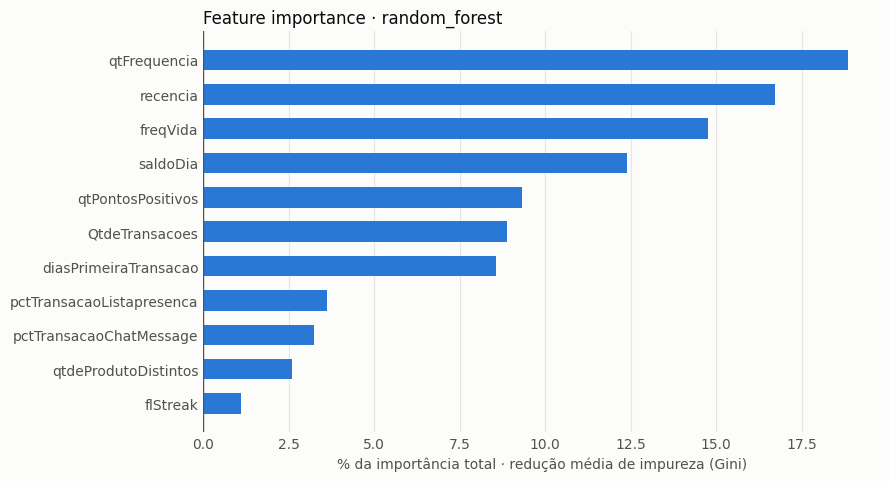

,feature,importancia,importancia_pct
0,qtFrequencia,0.188465,18.846485
1,recencia,0.167142,16.714161
2,freqVida,0.147569,14.756929
3,saldoDia,0.123872,12.387233
4,qtPontosPositivos,0.093164,9.316364
5,QtdeTransacoes,0.088727,8.872676
6,diasPrimeiraTransacao,0.085491,8.549093
7,pctTransacaoListapresenca,0.036298,3.629811
8,pctTransacaoChatMessage,0.032303,3.230316
9,qtdeProdutoDistintos,0.025835,2.583535


In [0]:
import pandas as pd
import matplotlib.pyplot as plt

# MODELO FINAL (treino + teste): o mesmo que vai para produção
melhor_clf = resultados[melhor_nome]["final_pipeline"].named_steps["classificador"]
print(f"Melhor algoritmo: {melhor_nome}")

def nomes_features(clf):
    """Nomes das features como o classificador as recebeu no treino (cada biblioteca guarda num atributo)."""
    for attr in ("feature_names_in_", "feature_name_", "feature_names_"):
        nomes = getattr(clf, attr, None)
        if nomes is not None:
            return [str(n) for n in nomes]
    raise AttributeError("Classificador sem nomes de features salvos")

# CADA BIBLIOTECA CALCULA A IMPORTÂNCIA NATIVA DE UM JEITO, E EM ESCALAS DIFERENTES.
# Por isso o gráfico usa % do total. No LightGBM, troca a contagem de splits (padrão) pelo gain.
if melhor_nome == "lightgbm":
    importancias = melhor_clf.booster_.feature_importance(importance_type="gain")
else:
    importancias = melhor_clf.feature_importances_

metodo_importancia = {
    "random_forest": "redução média de impureza (Gini)",
    "xgboost": "ganho médio nos splits (gain)",
    "catboost": "PredictionValuesChange",
    "lightgbm": "ganho total nos splits (gain)",
}

df_fi = (pd.DataFrame({"feature": nomes_features(melhor_clf),   # nomes vêm do próprio modelo
                       "importancia": importancias})
         .assign(importancia_pct=lambda d: 100 * d["importancia"] / d["importancia"].sum())
         .sort_values("importancia", ascending=False)
         .reset_index(drop=True))

# GRÁFICO: top N features (maior no topo)
top_n = 20
df_plot_fi = df_fi.head(top_n).iloc[::-1]

fig_fi, ax = plt.subplots(figsize=(9, 0.32 * len(df_plot_fi) + 1.4))
fig_fi.patch.set_facecolor("#fcfcfb")
ax.set_facecolor("#fcfcfb")

ax.barh(df_plot_fi["feature"], df_plot_fi["importancia_pct"], height=0.6, color="#2a78d6")
ax.axvline(0, color="#52514e", linewidth=1)

ax.set_title(f"Feature importance · {melhor_nome}", loc="left", color="#0b0b0b", fontsize=12)
ax.set_xlabel(f"% da importância total · {metodo_importancia.get(melhor_nome, 'importância nativa')}", color="#52514e")
ax.tick_params(colors="#52514e", length=0)
ax.grid(axis="x", color="#e6e5e1", linewidth=0.8)
ax.set_axisbelow(True)
for lado in ["top", "right", "left", "bottom"]:
    ax.spines[lado].set_visible(False)
plt.tight_layout()

# LOGA O GRÁFICO E A TABELA NA RUN DO MELHOR MODELO NO MLFLOW
run_id_melhor = comparacao.loc[comparacao["algoritmo"] == melhor_nome, "run_id"].iloc[0]
with mlflow.start_run(run_id=run_id_melhor):
    mlflow.log_figure(fig_fi, "feature_importance.png")
    mlflow.log_table(df_fi, "feature_importance.json")

plt.show()
df_fi

### Score da safra OOT
- Identifica a coluna de id do cliente: a primeira, entre as duas primeiras colunas, que não é `dtRef`.
- `prob_ativacao` = `predict_proba[:, 1]` do modelo final.
- `decil` (1 = maior probabilidade): o `rank(method="first")` desempata os scores, para que os decis
  tenham o mesmo tamanho.
- O resultado é ordenado da maior para a menor probabilidade de ativação.

No OOT o target já é conhecido, o que permite avaliar o score. Em produção, o mesmo fluxo seria
aplicado à `dtRef` mais recente, ainda sem target.

In [0]:
import pandas as pd

# USA O MODELO DEFINIDO NA CÉLULA DE DECISÃO (melhor_nome e final_pipe)
print(f"Modelo usado: {melhor_nome}")

col_id = [c for c in df_abt.columns[:2] if c != "dtRef"][0]  # coluna de ID do cliente (ajuste se necessário)

# PROBABILIDADE DE ATIVAÇÃO POR CLIENTE NA dtRef MAIS RECENTE
df_score = df_oot[["dtRef", col_id, target]].copy()
df_score["prob_ativacao"] = final_pipe.predict_proba(df_oot[features])[:, 1]

# DECIL: 1 = maior probabilidade
df_score["decil"] = pd.qcut(df_score["prob_ativacao"].rank(method="first", ascending=False),
                            10, labels=range(1, 11))

df_score = df_score.sort_values("prob_ativacao", ascending=False).reset_index(drop=True)
display(df_score)

Modelo usado: random_forest


dtRef,IdCliente,flAtivacao,prob_ativacao,decil
2026-06-01,a6e4050d-a9e0-4fcc-9022-b1d4d849f16f,1,0.9865391654469083,1
2026-06-01,520ec5df-4362-4dc5-8652-908676138114,1,0.9803603547958404,1
2026-06-01,2d3d2dce-d353-4961-ad39-46723efe2100,1,0.9801103291540527,1
2026-06-01,6313ceac-7806-4d34-aedd-476eed7c853a,1,0.9786770646194966,1
2026-06-01,9154669b-3725-411a-bffd-a833bbd60dc1,1,0.975308260659725,1
2026-06-01,451766e5-10d1-41f9-b176-ac3aa34e5a59,1,0.9744251228403347,1
2026-06-01,163022e8-12b8-486f-8604-57d8fa0ed7e1,1,0.9739731942063216,1
2026-06-01,5ed09fff-c0eb-48db-b6e3-20ef238e8b5c,1,0.9704487852300405,1
2026-06-01,820c0e06-c405-4979-8975-ecfa17abb0f9,1,0.969066166091067,1
2026-06-01,5ff083a7-e818-4367-bda5-a9cee8dec654,1,0.9687249767623932,1


### Probabilidade de churn
Define churn como o complemento da ativação: `prob_churn = 1 − prob_ativacao`.
Exibe o id do cliente e a probabilidade de churn dos 239 clientes do OOT.

> A tabela herda a ordenação da célula anterior (`prob_ativacao` decrescente), então os clientes de
> **maior risco de churn aparecem no fim**. A lista dos 50 clientes priorizados para retenção
> corresponde a `df_score.nlargest(50, "prob_churn")`.

In [0]:
df_score["prob_churn"] = 1 - df_score["prob_ativacao"]
display(df_score[[col_id, "prob_churn"]])

IdCliente,prob_churn
a6e4050d-a9e0-4fcc-9022-b1d4d849f16f,0.01346083455309166
520ec5df-4362-4dc5-8652-908676138114,0.019639645204159617
2d3d2dce-d353-4961-ad39-46723efe2100,0.019889670845947283
6313ceac-7806-4d34-aedd-476eed7c853a,0.02132293538050345
9154669b-3725-411a-bffd-a833bbd60dc1,0.02469173934027502
451766e5-10d1-41f9-b176-ac3aa34e5a59,0.025574877159665332
163022e8-12b8-486f-8604-57d8fa0ed7e1,0.026026805793678442
5ed09fff-c0eb-48db-b6e3-20ef238e8b5c,0.029551214769959477
820c0e06-c405-4979-8975-ecfa17abb0f9,0.030933833908933006
5ff083a7-e818-4367-bda5-a9cee8dec654,0.03127502323760678


### Assess: lift de ativação por faixa de score
Divide o OOT em `N_FAIXAS = 5` quintis de score (1 = maior probabilidade de ativação). Colunas da tabela:
- `taxa_real`: ativações / clientes da faixa
- `lift`: taxa da faixa / taxa média do OOT
- `lift_acumulado`: taxa da faixa 1 até a faixa k / taxa média
- `pct_ativacoes_capturadas`: % acumulado das ativações

No gráfico, as barras mostram o lift da faixa e a linha mostra o lift acumulado. O **lift máximo possível**
(1 / taxa média) é o lift de uma faixa em que todos ativam. A linha de 1,0× representa um modelo aleatório.

**Resultado:** taxa média de 56,1%, portanto o teto é 1,78×. A faixa 1 tem 100% de ativação
(lift 1,78×, igual ao teto) e os 40% do topo concentram 65,7% das ativações.

> Com uma taxa base alta, o teto do lift é baixo. Compare o lift com o teto, não com valores
> de outros modelos ou de outras safras.

n,ativacoes,prob_media,taxa_real,lift,lift_acumulado,pct_ativacoes_capturadas
48,48,0.9369388561163975,1.0,1.7835820895522387,1.7835820895522387,0.3582089552238806
48,40,0.5947323361059181,0.8333333333333334,1.486318407960199,1.6349502487562189,0.6567164179104478
47,22,0.3659775924610115,0.46808510638297873,0.8348682121308352,1.3719862227324915,0.8208955223880597
48,13,0.23283324236484412,0.2708333333333333,0.48305348258706465,1.1485895131671484,0.917910447761194
48,11,0.10728543570460398,0.22916666666666666,0.4087375621890547,1.0,1.0


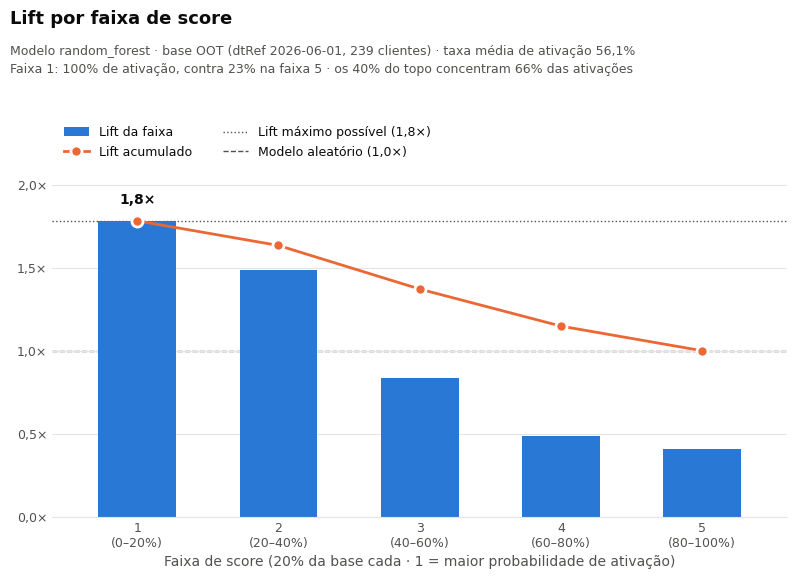

In [0]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, MaxNLocator

N_FAIXAS = 5                     # 5 = quintis (troque para 10 se quiser decis)
PCT_FAIXA = 100 // N_FAIXAS      # % da base em cada faixa

# FAIXA DE SCORE: 1 = maior probabilidade
df_score["faixa"] = pd.qcut(df_score["prob_ativacao"].rank(method="first", ascending=False),
                            N_FAIXAS, labels=range(1, N_FAIXAS + 1))

# TABELA DE LIFT POR FAIXA (OOT: base honesta, com o target observado)
taxa_media = df_score[target].mean()

lift = (df_score.groupby("faixa", observed=True)
        .agg(n=(target, "size"), ativacoes=(target, "sum"), prob_media=("prob_ativacao", "mean"))
        .sort_index())
lift["taxa_real"] = lift["ativacoes"] / lift["n"]
lift["lift"] = lift["taxa_real"] / taxa_media                                              # lift de cada faixa
lift["lift_acumulado"] = (lift["ativacoes"].cumsum() / lift["n"].cumsum()) / taxa_media    # da faixa 1 até a faixa k
lift["pct_ativacoes_capturadas"] = lift["ativacoes"].cumsum() / lift["ativacoes"].sum()
display(lift)

# GRÁFICO
COR_FAIXA, COR_ACUM = "#2a78d6", "#eb6834"
TEXTO_PRIMARIO, TEXTO_SECUNDARIO, GRADE = "#0b0b0b", "#52514e", "#e6e5e1"
fmt_x = lambda v: f"{v:.1f}×".replace(".", ",")
fmt_pct = lambda v, casas=1: f"{v:.{casas}%}".replace(".", ",")

x = np.arange(1, N_FAIXAS + 1)
lift_top = lift["lift"].iloc[0]
lift_max = 1 / taxa_media                         # teto: lift de uma faixa em que todos ativam
y_max = max(lift["lift"].max(), lift["lift_acumulado"].max(), lift_max) * 1.15

fig, ax = plt.subplots(figsize=(8, 5.8))
ax.bar(x, lift["lift"], width=0.55, color=COR_FAIXA, label="Lift da faixa", zorder=2)
ax.plot(x, lift["lift_acumulado"], color=COR_ACUM, linewidth=2, marker="o", markersize=8,
        markeredgecolor="white", markeredgewidth=2, label="Lift acumulado", zorder=3)
ax.axhline(lift_max, color=TEXTO_SECUNDARIO, linewidth=1, linestyle=":",
           label=f"Lift máximo possível ({fmt_x(lift_max)})", zorder=1)
ax.axhline(1, color=TEXTO_SECUNDARIO, linewidth=1, linestyle="--", label="Modelo aleatório (1,0×)", zorder=1)

# RÓTULO SÓ NA FAIXA 1 (a mensagem principal); os demais valores estão na tabela acima
ax.text(1, lift_top + y_max * 0.04, fmt_x(lift_top), ha="center", va="bottom",
        fontsize=10, fontweight="bold", color=TEXTO_PRIMARIO)

# EIXOS: passos "redondos" (0,2 / 0,5 / 1), que cabem em 1 casa decimal sem arredondar errado
ax.set_xticks(x)
ax.set_xticklabels([f"{i}\n({(i - 1) * PCT_FAIXA}–{i * PCT_FAIXA}%)" for i in x])
ax.set_xlim(0.4, N_FAIXAS + 0.6)
ax.set_ylim(0, y_max)
ax.yaxis.set_major_locator(MaxNLocator(nbins=6, steps=[1, 2, 5, 10]))
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: fmt_x(v)))
ax.set_xlabel(f"Faixa de score ({PCT_FAIXA}% da base cada · 1 = maior probabilidade de ativação)",
              fontsize=10, color=TEXTO_SECUNDARIO)
ax.grid(axis="y", color=GRADE, linewidth=0.8, zorder=0)
for lado in ["top", "right", "left"]:
    ax.spines[lado].set_visible(False)
ax.spines["bottom"].set_color(GRADE)
ax.tick_params(length=0, labelsize=9, labelcolor=TEXTO_SECUNDARIO)

# LEGENDA ACIMA DA ÁREA DO GRÁFICO, NA ORDEM: barras, linha, teto, aleatório
h, l = ax.get_legend_handles_labels()
ordem = [l.index("Lift da faixa"), l.index("Lift acumulado"),
         l.index(f"Lift máximo possível ({fmt_x(lift_max)})"), l.index("Modelo aleatório (1,0×)")]
ax.legend([h[i] for i in ordem], [l[i] for i in ordem], loc="lower left", bbox_to_anchor=(0, 1.02),
          ncol=2, frameon=False, fontsize=9, labelcolor=TEXTO_PRIMARIO, columnspacing=2.5)

# TÍTULO E SUBTÍTULO COM A LEITURA PRINCIPAL
n_clientes = f"{len(df_score):,}".replace(",", ".")
taxa_top, taxa_base = lift["taxa_real"].iloc[0], lift["taxa_real"].iloc[-1]
subtitulo = (f"Modelo {melhor_nome} · base OOT (dtRef {df_score['dtRef'].iloc[0]}, {n_clientes} clientes) · "
             f"taxa média de ativação {fmt_pct(taxa_media)}\n"
             f"Faixa 1: {fmt_pct(taxa_top, 0)} de ativação, contra {fmt_pct(taxa_base, 0)} na faixa {N_FAIXAS} · "
             f"os {2 * PCT_FAIXA}% do topo concentram "
             f"{fmt_pct(lift['pct_ativacoes_capturadas'].iloc[1], 0)} das ativações")
fig.text(0.01, 0.99, "Lift por faixa de score", ha="left", va="top",
         fontsize=13, fontweight="bold", color=TEXTO_PRIMARIO)
fig.text(0.01, 0.99 - 0.35 / fig.get_figheight(), subtitulo, ha="left", va="top",
         fontsize=9, color=TEXTO_SECUNDARIO, linespacing=1.5)
fig.tight_layout(rect=(0, 0, 1, 1 - 1.0 / fig.get_figheight()))
plt.show()

### Assess: lift de churn por faixa de risco
Mesma lógica da célula anterior, sob a ótica de retenção: `churn = 1 − flAtivacao`,
faixa 1 = maior probabilidade de churn.

**Resultado:** taxa média de churn de 43,9%, portanto o teto é 2,28×. A faixa 1 tem 77% de churn
(lift 1,75×), os 40% de maior risco concentram 68,6% dos churns e a faixa 5 não tem nenhum churn.

A faixa 1 (20% de maior risco, cerca de 48 clientes) é o público-alvo da ação de retenção; os 50
clientes priorizados praticamente coincidem com essa faixa.

> Esta célula sobrescreve as variáveis `lift` e `taxa_media` da célula anterior.

n,churns,prob_churn_media,taxa_churn,lift,lift_acumulado,pct_churns_capturados
48,37,0.892714564295396,0.7708333333333334,1.7545634920634923,1.7545634920634923,0.3523809523809524
48,35,0.767166757635156,0.7291666666666666,1.6597222222222223,1.7071428571428573,0.6857142857142857
47,25,0.6340224075389885,0.5319148936170213,1.210739614994934,1.5439893439893442,0.9238095238095239
48,8,0.4052676638940819,0.16666666666666666,0.37936507936507935,1.2513089005235603,1.0
48,0,0.06306114388360251,0.0,0.0,1.0,1.0


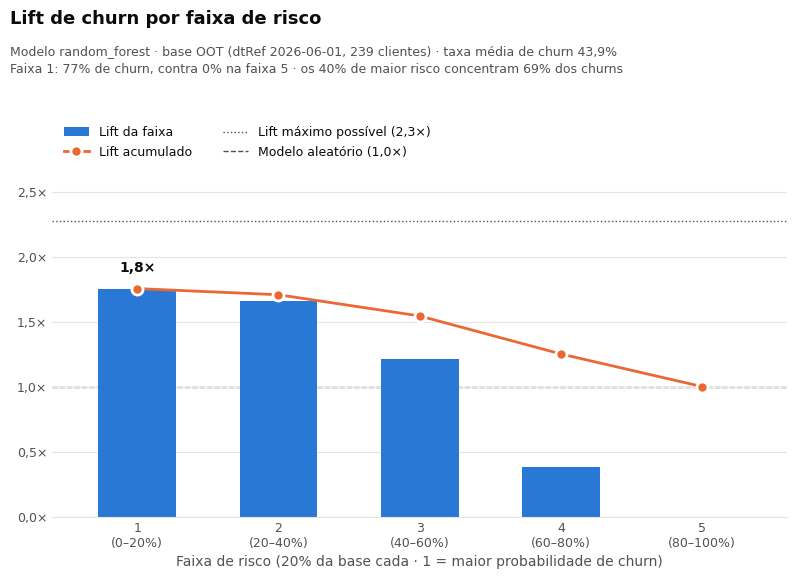

In [0]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, MaxNLocator

# PERSPECTIVA DE CHURN: churn = 1 - flAtivacao; quanto MENOR a prob_ativacao, MAIOR o risco
df_churn = df_score.copy()
df_churn["churn"] = 1 - df_churn[target]
df_churn["prob_churn"] = 1 - df_churn["prob_ativacao"]

N_FAIXAS = 5
PCT_FAIXA = 100 // N_FAIXAS

# FAIXA DE RISCO: 1 = maior probabilidade de churn
df_churn["faixa"] = pd.qcut(df_churn["prob_churn"].rank(method="first", ascending=False),
                            N_FAIXAS, labels=range(1, N_FAIXAS + 1))

taxa_media = df_churn["churn"].mean()

lift = (df_churn.groupby("faixa", observed=True)
        .agg(n=("churn", "size"), churns=("churn", "sum"), prob_churn_media=("prob_churn", "mean"))
        .sort_index())
lift["taxa_churn"] = lift["churns"] / lift["n"]
lift["lift"] = lift["taxa_churn"] / taxa_media
lift["lift_acumulado"] = (lift["churns"].cumsum() / lift["n"].cumsum()) / taxa_media
lift["pct_churns_capturados"] = lift["churns"].cumsum() / lift["churns"].sum()
display(lift)

# GRÁFICO
COR_FAIXA, COR_ACUM = "#2a78d6", "#eb6834"
TEXTO_PRIMARIO, TEXTO_SECUNDARIO, GRADE = "#0b0b0b", "#52514e", "#e6e5e1"
fmt_x = lambda v: f"{v:.1f}×".replace(".", ",")
fmt_pct = lambda v, casas=1: f"{v:.{casas}%}".replace(".", ",")

x = np.arange(1, N_FAIXAS + 1)
lift_top = lift["lift"].iloc[0]
lift_max = 1 / taxa_media                         # teto: lift de uma faixa em que todos dão churn
y_max = max(lift["lift"].max(), lift["lift_acumulado"].max(), lift_max) * 1.15

fig, ax = plt.subplots(figsize=(8, 5.8))
ax.bar(x, lift["lift"], width=0.55, color=COR_FAIXA, label="Lift da faixa", zorder=2)
ax.plot(x, lift["lift_acumulado"], color=COR_ACUM, linewidth=2, marker="o", markersize=8,
        markeredgecolor="white", markeredgewidth=2, label="Lift acumulado", zorder=3)
ax.axhline(lift_max, color=TEXTO_SECUNDARIO, linewidth=1, linestyle=":",
           label=f"Lift máximo possível ({fmt_x(lift_max)})", zorder=1)
ax.axhline(1, color=TEXTO_SECUNDARIO, linewidth=1, linestyle="--", label="Modelo aleatório (1,0×)", zorder=1)

# RÓTULO SÓ NA FAIXA 1 (a mensagem principal)
ax.text(1, lift_top + y_max * 0.04, fmt_x(lift_top), ha="center", va="bottom",
        fontsize=10, fontweight="bold", color=TEXTO_PRIMARIO)

ax.set_xticks(x)
ax.set_xticklabels([f"{i}\n({(i - 1) * PCT_FAIXA}–{i * PCT_FAIXA}%)" for i in x])
ax.set_xlim(0.4, N_FAIXAS + 0.6)
ax.set_ylim(0, y_max)
ax.yaxis.set_major_locator(MaxNLocator(nbins=6, steps=[1, 2, 5, 10]))
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: fmt_x(v)))
ax.set_xlabel(f"Faixa de risco ({PCT_FAIXA}% da base cada · 1 = maior probabilidade de churn)",
              fontsize=10, color=TEXTO_SECUNDARIO)
ax.grid(axis="y", color=GRADE, linewidth=0.8, zorder=0)
for lado in ["top", "right", "left"]:
    ax.spines[lado].set_visible(False)
ax.spines["bottom"].set_color(GRADE)
ax.tick_params(length=0, labelsize=9, labelcolor=TEXTO_SECUNDARIO)

h, l = ax.get_legend_handles_labels()
ordem = [l.index("Lift da faixa"), l.index("Lift acumulado"),
         l.index(f"Lift máximo possível ({fmt_x(lift_max)})"), l.index("Modelo aleatório (1,0×)")]
ax.legend([h[i] for i in ordem], [l[i] for i in ordem], loc="lower left", bbox_to_anchor=(0, 1.02),
          ncol=2, frameon=False, fontsize=9, labelcolor=TEXTO_PRIMARIO, columnspacing=2.5)

n_clientes = f"{len(df_churn):,}".replace(",", ".")
taxa_top, taxa_base = lift["taxa_churn"].iloc[0], lift["taxa_churn"].iloc[-1]
subtitulo = (f"Modelo {melhor_nome} · base OOT (dtRef {df_churn['dtRef'].iloc[0]}, {n_clientes} clientes) · "
             f"taxa média de churn {fmt_pct(taxa_media)}\n"
             f"Faixa 1: {fmt_pct(taxa_top, 0)} de churn, contra {fmt_pct(taxa_base, 0)} na faixa {N_FAIXAS} · "
             f"os {2 * PCT_FAIXA}% de maior risco concentram "
             f"{fmt_pct(lift['pct_churns_capturados'].iloc[1], 0)} dos churns")
fig.text(0.01, 0.99, "Lift de churn por faixa de risco", ha="left", va="top",
         fontsize=13, fontweight="bold", color=TEXTO_PRIMARIO)
fig.text(0.01, 0.99 - 0.35 / fig.get_figheight(), subtitulo, ha="left", va="top",
         fontsize=9, color=TEXTO_SECUNDARIO, linespacing=1.5)
fig.tight_layout(rect=(0, 0, 1, 1 - 1.0 / fig.get_figheight()))
plt.show()